##                                                   Real-Time Fraud Detection

In [42]:
pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn joblib streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [43]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [44]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import plotly.express as px
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score , precision_score , recall_score, classification_report

import warnings
warnings.filterwarnings('ignore')

ModuleNotFoundError: No module named 'plotly'

## Load & first look

In [ ]:
df = pd.read_csv("creditcard.csv")

## EDA

In [ ]:
print(df.shape)
df.info()
df.head()

(284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
df.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

In [ ]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.596686e-16,-3.576577e-16,2.618565e-16,4.473116e-15,5.109395e-16,1.686100e-15,-3.657409e-16,-1.221465e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


## Data quality audit

In [ ]:
def quality_report(data):
    report = pd.DataFrame({
        "dtype":    data.dtypes,
        "nulls":    data.isna().sum(),
        "null_pct": (data.isna().mean() * 100).round(1),
        "unique":   data.nunique(),
    })
    return report

quality_report(df)

,dtype,nulls,null_pct,unique
Time,float64,0,0.0,124592
V1,float64,0,0.0,275663
V2,float64,0,0.0,275663
V3,float64,0,0.0,275663
V4,float64,0,0.0,275663
V5,float64,0,0.0,275663
V6,float64,0,0.0,275663
V7,float64,0,0.0,275663
V8,float64,0,0.0,275663
V9,float64,0,0.0,275663


In [ ]:
print("Total rows:", len(df))

Total rows: 284807


In [ ]:
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")
df = df.drop_duplicates()

0 missing values
1081 duplicate rows


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## Inconsistencies

In [ ]:
print("Infinite values:", np.isinf(df.select_dtypes("number")).sum().sum())
print("Negative amounts:", (df["Amount"] < 0).sum())
print("Invalid Class values:", (~df["Class"].isin([0, 1])).sum())
print("Zero amounts:", (df["Amount"] == 0).sum())
print("Time sorted:", df["Time"].is_monotonic_increasing)

Infinite values: 0
Negative amounts: 0
Invalid Class values: 0
Zero amounts: 1808
Time sorted: True


In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
df = df.replace([np.inf, -np.inf], np.nan).dropna()
df = df[df["Amount"] >= 0]
df = df[df["Class"].isin([0, 1])].reset_index(drop=True)

print(df.shape)
print(df["Class"].value_counts())

(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


In [ ]:
df['Class'].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

In [ ]:
fraud = df[df['Class'] == 1]
non_fraud = df[df['Class'] == 0]


In [ ]:
fraud.Amount.describe()


count     473.000000
mean      123.871860
std       260.211041
min         0.000000
25%         1.000000
50%         9.820000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

In [ ]:
non_fraud.Amount.describe()

count    283253.000000
mean         88.413575
std         250.379023
min           0.000000
25%           5.670000
50%          22.000000
75%          77.460000
max       25691.160000
Name: Amount, dtype: float64

## Class Distribution (Fraud vs Non-Fraud)

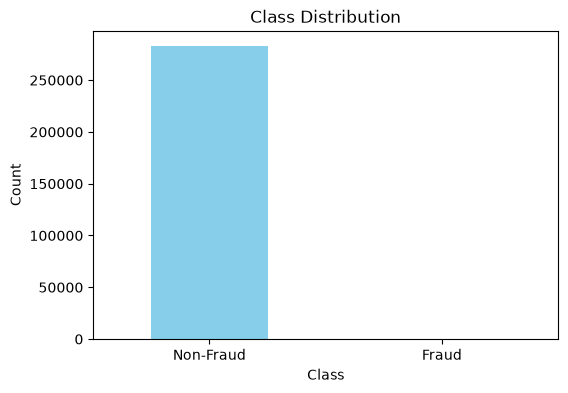

In [ ]:
class_counts = df['Class'].value_counts()
class_labels = ['Non-Fraud', 'Fraud']
plt.figure(figsize=(6, 4))
class_counts.plot(kind='bar', color=['skyblue', 'orange'])
plt.title('Class Distribution')
plt.xticks(ticks=[0, 1], labels=class_labels, rotation=0)
plt.ylabel('Count')
plt.show()

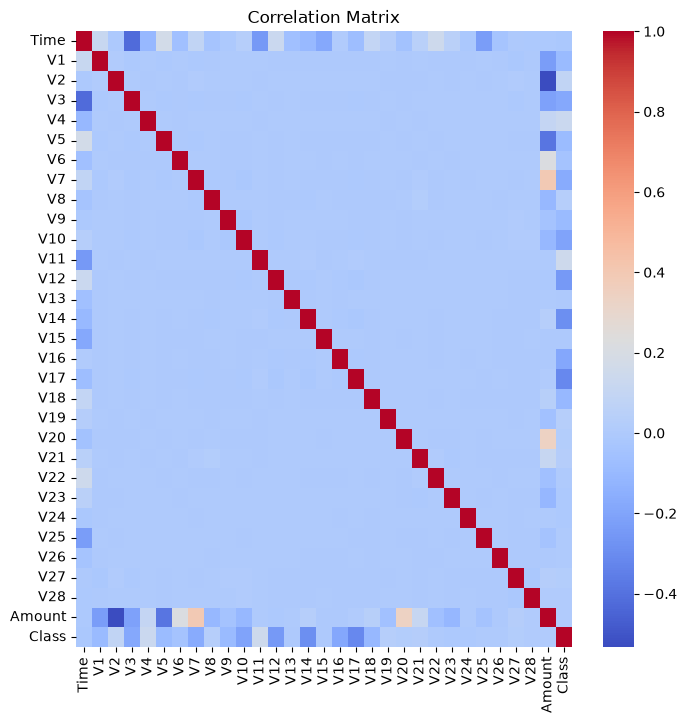

In [ ]:
plt.figure(figsize=(8, 8))
sns.heatmap(df.corr(), cmap='coolwarm', annot=False, fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

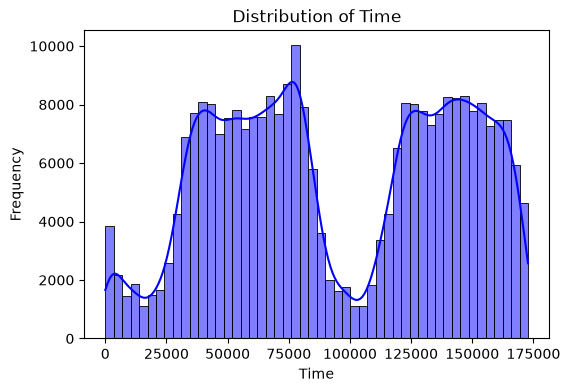

In [ ]:
plt.figure(figsize=(6, 4))
sns.histplot(df['Time'], bins=50, kde=True, color='blue')
plt.title('Distribution of Time')
plt.xlabel('Time')
plt.ylabel('Frequency')
plt.show()

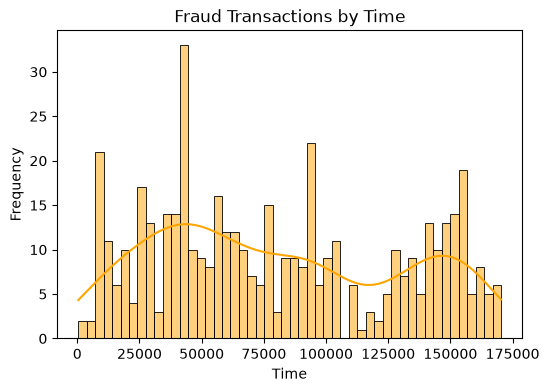

In [ ]:
plt.figure(figsize=(6, 4))
sns.histplot(fraud['Time'], bins=50, kde=True, color='orange')
plt.title('Fraud Transactions by Time')
plt.xlabel('Time')
plt.ylabel('Frequency')
plt.show()

## OUTLIERS

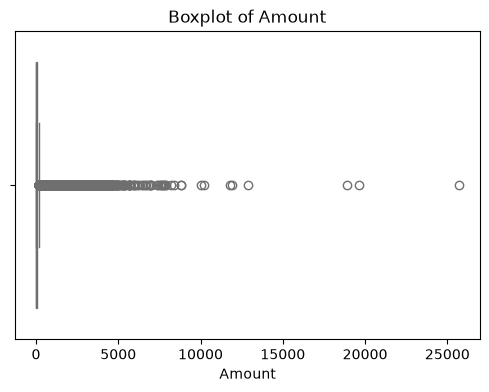

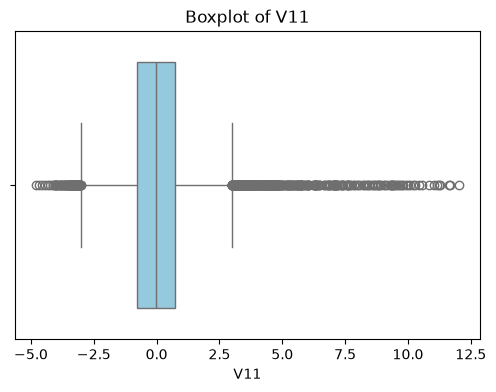

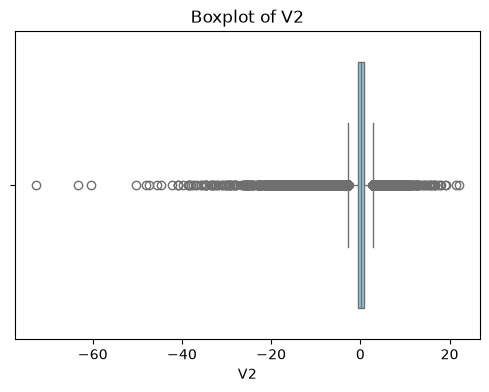

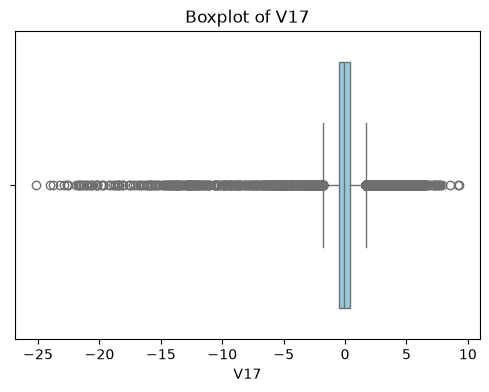

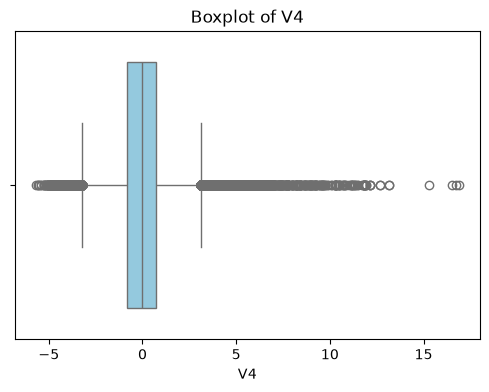

In [ ]:
features = ['Amount', 'V11', 'V2', 'V17', 'V4']
for feature in features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[feature], color='skyblue')
    plt.title(f'Boxplot of {feature}')
    plt.xlabel(feature)
    plt.show()

In [ ]:
X=df.drop(columns='Class')

y=df['Class']

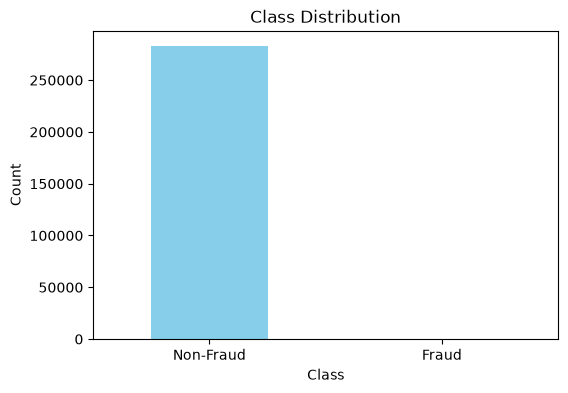

In [ ]:
class_counts = y.value_counts()
class_labels = ['Non-Fraud', 'Fraud']
plt.figure(figsize=(6, 4))
class_counts.plot(kind='bar', color=['skyblue', 'orange'])
plt.title('Class Distribution')
plt.xticks(ticks=[0, 1], labels=class_labels, rotation=0)
plt.ylabel('Count')
plt.show()

## Challenges of Imbalanced Data

#### Model Bias:

Most models optimize for overall accuracy, which means they may ignore the minority class entirely. Example: A model predicting "Non-Fraud" for all transactions would achieve 99.8% accuracy but fail to identify fraud.

Metrics Misrepresentation:

Accuracy alone is not a reliable metric for imbalanced datasets. Precision, recall, F1-score, and confusion matrix become more important.

Why Use stratify=y?

stratify=y ensures that the class distribution in the y target variable is maintained in both training and test sets.

Stratified Splitting:

Preserves the proportion of each class during the split.

Ensures the training and test sets are representative of the overall dataset.

Importance for Imbalanced Datasets:

Prevents underrepresented classes from being excluded in one of the subsets.

Leads to fair evaluation by maintaining consistent class proportions.

## Model

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test= train_test_split(X,y,test_size=.2,random_state=42, stratify=y)

## SMOTE (Synthetic Minority Oversampling Technique):
is a resampling method used to address class imbalance in datasets by creating synthetic examples of the minority class.

## Benefits of Using SMOTE:
Improves Model Performance on Imbalanced Data:

Balances the class distribution, helping the model learn patterns from the minority class. Reduces the risk of the model being biased toward the majority class. Avoids Overfitting:

Unlike random oversampling, which duplicates existing data, SMOTE creates new, slightly varied data points, reducing overfitting. Maintains Feature Relationships:

Synthetic samples are based on existing data, ensuring that the feature space remains realistic.

In [ ]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

## Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
LG = LogisticRegression()
LG.fit(X_train_resampled, y_train_resampled)

C:\Users\vaish\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [ ]:
y_pred_Test = LG.predict(X_test)
y_predTrain=LG.predict(X_train_resampled)

In [ ]:
y_predTest=LG.predict(X_test)
y_predTrain=LG.predict(X_train_resampled)

In [ ]:
from sklearn.metrics import accuracy_score

print("\nAccuracy Score:")

print(f"Train Accuracy: {accuracy_score(y_train_resampled, y_predTrain)}")

print(f"Test Accuracy: {accuracy_score(y_test, y_predTest)}")


Accuracy Score:
Train Accuracy: 0.9730121534673127
Test Accuracy: 0.9810206886829027


In [ ]:
print("\nRecall Score:")

print(f"Train Recall: {recall_score(y_train_resampled, y_predTrain)}")

print(f"Test Recall: {recall_score(y_test, y_predTest)}")


Recall Score:


NameError: name 'recall_score' is not defined

In [ ]:
print("\nClassification Report (Test):")
print(classification_report(y_test, y_predTest))


Classification Report (Test):
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.08      0.88      0.14        95

    accuracy                           0.98     56746
   macro avg       0.54      0.93      0.57     56746
weighted avg       1.00      0.98      0.99     56746



In [ ]:
print("Confusion Matrix (Test):")
print(confusion_matrix(y_test, y_predTest))

Confusion Matrix (Test):
[[55651  1000]
 [   11    84]]


## XGBClassifier

In [ ]:
model = XGBClassifier(
    n_estimators=500,          # Reduce the number of trees
    learning_rate=0.1,         # Use a smaller learning rate
    max_depth=4,               # Reduce tree depth
    min_child_weight=3,        # Increase minimum child weight
    subsample=0.7,             # Use a subset of the data for training
    colsample_bytree=0.7,      # Use a subset of features for training
    gamma=1,                   # Minimum loss reduction required for split
    reg_alpha=2,               # Increase L1 regularization
    reg_lambda=2               # Increase L2 regularization
)
model.fit(X_train_resampled,y_train_resampled)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=1, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=3, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=500,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X, y, cv=skf, scoring='accuracy')
y_predTest=model.predict(X_test)
y_predTrain=model.predict(X_train_resampled)

## Evaluation

In [ ]:
print("\nAccuracy Score:")
print(f"Train Accuracy: {accuracy_score(y_train_resampled, y_predTrain)}")
print(f"Test Accuracy: {accuracy_score(y_test, y_predTest)}")
print(f"Cross-Validation Accuracy: {cv_scores.mean():.4f}")


Accuracy Score:
Train Accuracy: 0.9999338046442662
Test Accuracy: 0.9992069925633524
Cross-Validation Accuracy: 0.9996


In [ ]:
print("\nPrecision Score:")

print(f"Train Precision: {precision_score(y_train_resampled, y_predTrain)}")

print(f"Test Precision: {precision_score(y_test, y_predTest)}")


Precision Score:
Train Precision: 0.9998676268135126
Test Precision: 0.7450980392156863


In [ ]:
print("\nRecall Score:")

print(f"Train Recall: {recall_score(y_train_resampled, y_predTrain)}")

print(f"Test Recall: {recall_score(y_test, y_predTest)}")


Recall Score:
Train Recall: 1.0
Test Recall: 0.8


In [ ]:
print("\nClassification Report (Test):")

print(classification_report(y_test, y_predTest))


Classification Report (Test):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.75      0.80      0.77        95

    accuracy                           1.00     56746
   macro avg       0.87      0.90      0.89     56746
weighted avg       1.00      1.00      1.00     56746



In [ ]:
print("Confusion Matrix (Test):")

print(confusion_matrix(y_test, y_predTest))

Confusion Matrix (Test):
[[56625    26]
 [   19    76]]


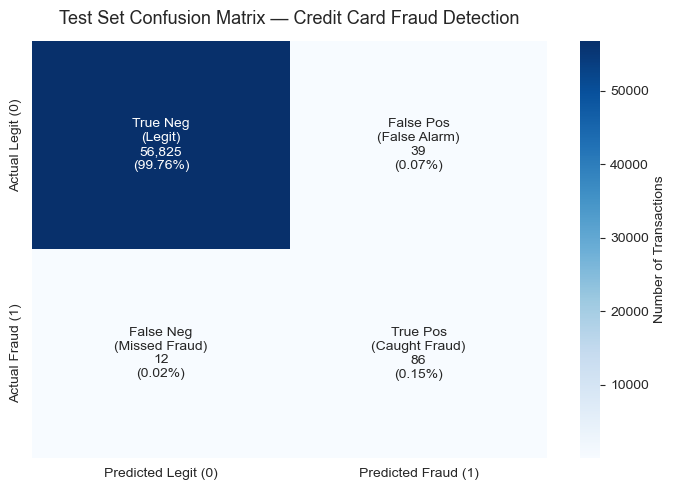

In [ ]:

# Test confusion matrix values: [[TN, FP], [FN, TP]]
cm = np.array([[56825, 39], [12, 86]])

# Labels for each quadrant to make the plot self-explanatory
group_names = ["True Neg\n(Legit)", "False Pos\n(False Alarm)", "False Neg\n(Missed Fraud)", "True Pos\n(Caught Fraud)"]
group_counts = [f"{value:,}" for value in cm.flatten()]
group_percentages = [f"{value/np.sum(cm):.2%}" for value in cm.flatten()]

cell_labels = [
    f"{name}\n{count}\n({pct})"
    for name, count, pct in zip(group_names, group_counts, group_percentages)
]
cell_labels = np.asarray(cell_labels).reshape(2, 2)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=cell_labels,
    fmt="",
    cmap="Blues",
    xticklabels=["Predicted Legit (0)", "Predicted Fraud (1)"],
    yticklabels=["Actual Legit (0)", "Actual Fraud (1)"],
    cbar_kws={"label": "Number of Transactions"},
)

plt.title("Test Set Confusion Matrix — Credit Card Fraud Detection", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

In [ ]:
# Saves your trained XGBoost model.

import joblib, os
os.makedirs("models", exist_ok=True)
os.makedirs("data", exist_ok=True)

joblib.dump(model, "models/model.pkl", compress=3)   

NameError: name 'model' is not defined

In [45]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=4,
    min_child_weight=3,
    subsample=0.7,
    colsample_bytree=0.7,
    gamma=1,
    reg_alpha=2,
    reg_lambda=2
)

model.fit(X_train_resampled, y_train_resampled)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.7
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
# Creates a small (~3 MB) file to replay as the live stream. The full 144 MB file can't go on GitHub.
demo = pd.concat([df[df["Class"] == 1], df[df["Class"] == 0].sample(10000, random_state=42)])
demo = demo.sample(frac=1, random_state=42)
demo.to_csv("data/demo_stream.csv", index=False)
print(demo.shape)                                 

(10473, 31)


In [46]:

import os
import joblib

# Create folders automatically
os.makedirs("models", exist_ok=True)
os.makedirs("data", exist_ok=True)

# Save the trained XGBoost model
joblib.dump(model, "models/model.pkl")

# Save sample transactions for Streamlit
demo_data = X_test.sample(
    n=min(100, len(X_test)),
    random_state=42
)

demo_data.to_csv("data/demo_stream.csv", index=False)

print("Model and demo data saved successfully!")


Model and demo data saved successfully!


In [47]:
import os

print("Model file exists:", os.path.exists("models/model.pkl"))
print("Demo data exists:", os.path.exists("data/demo_stream.csv"))

print("Project folder:", os.getcwd())

Model file exists: True
Demo data exists: True
Project folder: c:\Users\vaish\Downloads\Fraud Detection
